In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [4]:
df = pd.read_csv(r"C:\Users\Siddarood\Data Science 2\DS Morning 9th Feb 2026\DS Morning 9th Feb 2026\DB_dataset.csv")

In [5]:
df.shape

(500, 2)

In [6]:
df.head()

,Weight,Height
0,67.062924,176.086355
1,68.804094,178.388668
2,60.930863,170.284496
3,59.733843,168.691992
4,65.431230,173.763679


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().sum()

Weight    0
Height    0
dtype: int64

In [9]:
std_sca = StandardScaler()
features = pd.DataFrame(std_sca.fit_transform(df),columns=df.columns)
features.head()

,Weight,Height
0,1.115742,1.368788
1,1.451113,1.848408
2,-0.065368,0.160139
3,-0.295929,-0.171612
4,0.801458,0.884926


For finding the best eps(no_of clusters) value we have one best approach called nearestneighbour this will tell us if how much no of cluster we give the model will give best result.

In [10]:
from sklearn.neighbors import NearestNeighbors
n_neigh = NearestNeighbors(n_neighbors=10)
n_neigh.fit(features)

,n_neighbors,10
,radius,1.0
,algorithm,'auto'
,leaf_size,30
,metric,'minkowski'
,p,2
,metric_params,None
,n_jobs,None


In [11]:
distance, index= n_neigh.kneighbors(features)

In [12]:
distance[0]

array([0.        , 0.01507492, 0.0245175 , 0.0451716 , 0.04921661,
       0.05022186, 0.05572872, 0.05659828, 0.06039896, 0.06667069])

In [13]:
index[0]

array([  0, 353, 329, 119, 287, 274,  16, 221, 282,  59])

In [14]:
distance1=sorted(distance[:,1])

* From each row it will take the seond value bcs it's the pt present in the closest distance. This saved in ascending order.
* That sorted values are plotted in the below graph

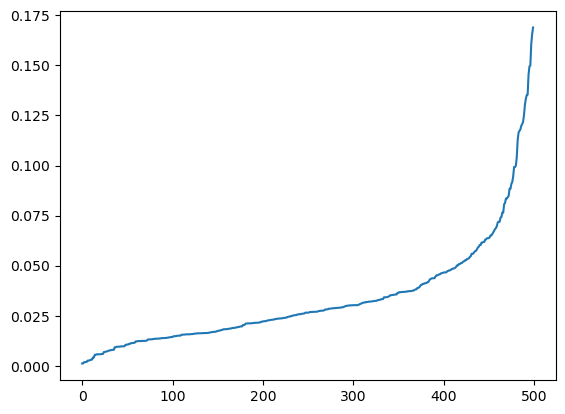

In [15]:
plt.plot(distance1)

* Y_axis pts are optimzed eps values.
* From elbow(bend) the above pts that can be taken as the eps.
* To check on which eps value it giving best "siloutte score" followed the bellow process.

In [19]:
eps = np.arange(0.1,0.65,0.05)
eps
# This will create 0.1 to 0.6 with interval of 0.05 in bw

array([0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 , 0.55, 0.6 ])

In [18]:
min_nodes = range(1,15)

In [21]:
output=[]
for i in eps:
    for j in min_nodes:
        labels = DBSCAN(eps=i,min_samples=j).fit(features).labels_
        score = silhouette_score(features,labels)
        output.append([i,j,score])
print(output)

[[np.float64(0.1), 1, -0.04299681057231643], [np.float64(0.1), 2, 0.2832200472847609], [np.float64(0.1), 3, 0.42737747491884875], [np.float64(0.1), 4, 0.5359027025302264], [np.float64(0.1), 5, 0.4827750201294571], [np.float64(0.1), 6, 0.4076103765285375], [np.float64(0.1), 7, 0.4749535686603094], [np.float64(0.1), 8, 0.36094434711787066], [np.float64(0.1), 9, 0.3333993335941656], [np.float64(0.1), 10, 0.3612527257725542], [np.float64(0.1), 11, 0.24566886958458425], [np.float64(0.1), 12, 0.28616029787680874], [np.float64(0.1), 13, 0.16442105873682414], [np.float64(0.1), 14, 0.11545446878821204], [np.float64(0.15000000000000002), 1, 0.34240912048557104], [np.float64(0.15000000000000002), 2, 0.6692399760277197], [np.float64(0.15000000000000002), 3, 0.6692399760277197], [np.float64(0.15000000000000002), 4, 0.6889396445365334], [np.float64(0.15000000000000002), 5, 0.6889396445365334], [np.float64(0.15000000000000002), 6, 0.6758937252010052], [np.float64(0.15000000000000002), 7, 0.6589548495

* So through loop is plotting first it take from eps first value 0.1 and it take first min node starting value as 1 and calculate the silhoutte score give that output in the list of empty output this step done for all the nodes. after that it take after 0.1 next value present in the eps i.e 0.15 and calculta sil_score for all the min_nodes given. and on which node the highest sillhoute score is giving that eps and node value to be taken.

In [22]:
eps,min_nodes,score = sorted(output, reverse=True, key= lambda x: x[2])[0]
print('eps:',eps, 'min_node:', min_nodes , 'Sil_score:', score)

eps: 0.20000000000000004 min_node: 12 Sil_score: 0.69715225450805


* Here the lambda key sorting the values with respect to score

* bcs in the key parameter we are using the x[2] so it refering the index poisiton in the ouput i.e score)

* [0] is the giving the fist ouput to show

In [29]:
labels = DBSCAN(eps=0.2, min_samples=12).fit(features).labels_
np.unique(labels)
# This are the different types of cluster groups 
# present in the dataset and -1 is the outliers

array([-1,  0,  1,  2])

In [31]:
np.where(labels<0)
# This are the index values of the outliers present in
# the data.

(array([ 35,  52, 166, 182, 209, 240, 343, 344, 357, 429, 464, 479, 498]),)

<Axes: xlabel='Weight', ylabel='Height'>

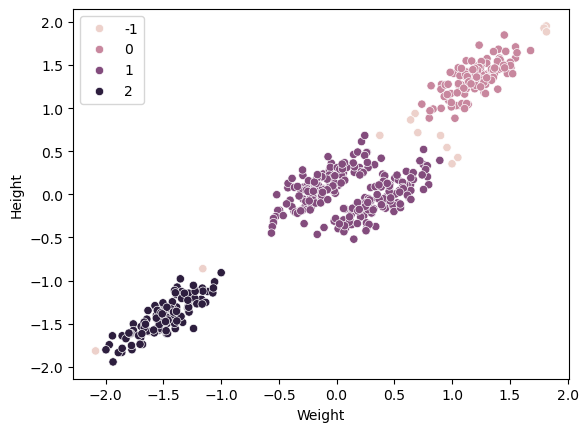

In [32]:
sns.scatterplot(data=features,x='Weight',y='Height',hue=labels)

####  This are the different types are groups present in the dataset here we can see that the -1 are the Outlier. and 0,1,2 are different outlier groups.